<a href="https://colab.research.google.com/github/Zaid-Ahmed27/4-channel-system-using-void-function/blob/main/Ai_%26_Ml_Project_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

uploaded = files.upload()
floor_plan = pd.read_csv("mydata.csv")

print(floor_plan.head(30))

Saving mydata.csv to mydata.csv
    PosX  PosY  PosZ         SSID              BSSID  RSSI
0    162   251     4       HV-COF  48:8b:0a:cb:5e:a1   -63
1    162   251     4     HV-GUEST  48:8b:0a:cb:5e:a2   -63
2    162   251     4    HV-HYBRID  48:8b:0a:cb:5e:a3   -63
3    162   251     4      eduroam  48:8b:0a:cb:5e:a0   -63
4    162   251     4      eduroam  24:d7:9c:90:99:20   -64
5    162   251     4    HV-HYBRID  24:d7:9c:90:99:23   -65
6    162   251     4       HV-COF  24:d7:9c:90:99:21   -66
7    162   251     4     HV-GUEST  24:d7:9c:90:99:22   -66
8    162   251     4  HV-INTERNAL  24:d7:9c:90:99:24   -66
9    162   251     4    HV-HYBRID  48:8b:0a:cb:68:c3   -68
10   162   251     4       HV-COF  24:d7:9c:90:99:2e   -69
11   162   251     4       HV-COF  48:8b:0a:cb:68:c1   -69
12   162   251     4     HV-GUEST  48:8b:0a:cb:68:c2   -69
13   162   251     4  HV-INTERNAL  48:8b:0a:cb:68:c4   -69
14   162   251     4      eduroam  24:d7:9c:90:99:2f   -70
15   162   251     4    

In [2]:
print(floor_plan.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 447814 entries, 0 to 447813
Data columns (total 6 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   PosX    447814 non-null  int64 
 1   PosY    447814 non-null  int64 
 2   PosZ    447814 non-null  int64 
 3   SSID    447814 non-null  object
 4   BSSID   447814 non-null  object
 5   RSSI    447814 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 20.5+ MB
None


In [3]:
print(floor_plan.describe())


                PosX           PosY           PosZ           RSSI
count  447814.000000  447814.000000  447814.000000  447814.000000
mean     1010.201912    1392.930871       2.920827     -80.429122
std       505.413752     660.943325       0.795296       8.081829
min       162.000000     251.000000       2.000000     -97.000000
25%       560.000000     611.000000       2.000000     -87.000000
50%      1021.000000    1404.000000       3.000000     -82.000000
75%      1456.000000    2118.000000       4.000000     -75.000000
max      1897.000000    2242.000000       4.000000     -48.000000


In [4]:
######### Preprocessing the data for Polynomial Regression  ########

## Defining the target (y) and Features (x)
y = floor_plan['PosZ']
x = floor_plan.drop(columns=['PosZ'])

## Note: We have categorical values(SSID and BSSID), if we use one-hot encoder on BSSID then we might
## end up with thousands of new columns and when we apply polynomial regression(degree) to it, then
## it will create million of new features and cause Out-of-memory error.


## for a successful first run we will drop the BSSID
x = x.drop(columns=['BSSID'])


## One-hot-Encode the SSID values
x = pd.get_dummies(x, columns=['SSID'], drop_first=True)

## Ensuring that all data is float for Polynomial Regression
x = x.astype(float)


In [5]:

##### Splitting the data into Train/Split sets

x_train, x_test, y_train, y_test =train_test_split(x, y, test_size = 0.2, random_state = 42)

In [6]:
##### Creating the Polynomial Regression pipeline

## Note: Standard scaler is used because PosX and PosY has large numbers of data and
## the RSSI values are all negative.


model = Pipeline([
    ('scaler',StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('regressor', LinearRegression())
      ])

## Training the model
model.fit(x_train, y_train)


Pipeline(steps=[('scaler', StandardScaler()),
                ('poly', PolynomialFeatures(include_bias=False)),
                ('regressor', LinearRegression())])

In [7]:
##### Predicting and evaluating the values

y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R-squared score: {r2:.4f}")  ## the .4f show values to 4 decimal place

Mean Squared Error: 4.073260152464156e-06
R-squared score: 1.0000


In [12]:
######################   Apply Decision Tree Regressor ##################

######### Preprocessing the data for Decision Tree Regressor  ########

from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import LabelEncoder

## Note: instead of one-hot-encoder we are using Label-Encoder, this will assign
## a unique integer to each string.
## We will be doing this for SSID and BSSID

floor_plan_DT = floor_plan.copy()

## Defining the Features and target
dt_x = floor_plan_DT.drop(columns=['PosZ'])
dt_y = floor_plan_DT['PosZ']

## Note: Decision Trees can handle high cardinality unlike Polynomial Regressor,
## so will be keeping BSSID this time.

le_ssid = LabelEncoder()
le_bssid = LabelEncoder()

dt_x['SSID'] = le_ssid.fit_transform(dt_x['SSID'])
dt_x['BSSID'] = le_bssid.fit_transform(dt_x['BSSID'])


#### Optional: drop PosX and PosY to get pure wifi-fingerprinting

## dt_x = dt_x.drop(columns=['PosX','PosY'])


In [17]:
##### Splitting the data into Train/Split sets

dt_x_train, dt_x_test, dt_y_train, dt_y_test =train_test_split(dt_x, dt_y, test_size = 0.2, random_state = 42)

dt_model = DecisionTreeRegressor(max_depth=15, min_samples_leaf=60, random_state=42)
dt_model.fit(dt_x_train, dt_y_train)

DecisionTreeRegressor(max_depth=15, min_samples_leaf=60, random_state=42)

In [18]:
####### Evaluating the model

## Predicting the values
dt_y_pred_train = dt_model.predict(dt_x_train)
dt_y_pred_test = dt_model.predict(dt_x_test)


## Calculating the error
mse_train = mean_squared_error(dt_y_train, dt_y_pred_train)
mse_test = mean_squared_error(dt_y_test, dt_y_pred_test)

r2_train = r2_score(dt_y_train, dt_y_pred_train)
r2_test = r2_score(dt_y_test, dt_y_pred_test)


## Evaluating the model
print(f"Mean Squared Error (Train): {mse_train:.4f} | R2_Train: {r2_train:.4f}")
print(f"Mean Squared Error (Test): {mse_test:.4f} | R2_Test: {r2_test:.4f}")


Mean Squared Error (Train): 0.0000 | R2_Train: 1.0000
Mean Squared Error (Test): 0.0000 | R2_Test: 1.0000


In [25]:
######################   Applying Mini-Batch Kmeans algorithm ##################


import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import MiniBatchKMeans

floor_plan_Kmeans = floor_plan.copy()

## Optional: drop duplicates to prevent clusters from being skewed by redundant data
##floor_plan_Kmeans = floor_plan_Kmeans.drop_duplicates()

## We will make clusters based on physical positions (PosX and PosY)
## We drop PosZ so the algorithm can't cheat
x_Kmeans = floor_plan_Kmeans[['PosX','PosY']]

## Scaling the data
scaler = StandardScaler()
x_scaled_Kmeans = scaler.fit_transform(x_Kmeans)

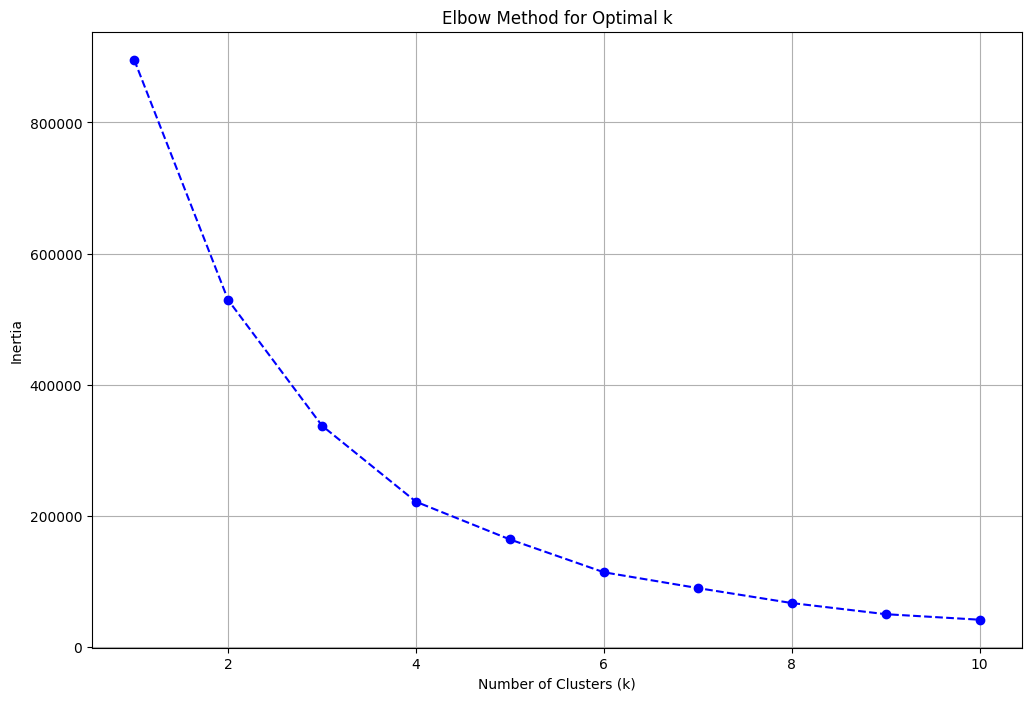

In [26]:
## Calculating the inertia for k=1 to 10
## We are checking for the elbow point of inertia

inertia = []
k_range = range(1, 11)

## calculating the inertia for elbow position
for k in k_range:
    kmeans = MiniBatchKMeans(n_clusters=k, random_state=42, batch_size=1000, n_init='auto')
    kmeans.fit(x_scaled_Kmeans)
    inertia.append(kmeans.inertia_)


## plotting the elbow
plt.figure(figsize=(12, 8))
plt.plot(k_range, inertia, marker='o', linestyle='--', color='b')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [27]:
#### Training the final model

optimal_k = 5

kmeans = MiniBatchKMeans(n_clusters=optimal_k, random_state=42, batch_size=1000, n_init='auto')
clsuter_labels = kmeans.fit_predict(x_scaled_Kmeans)

floor_plan_Kmeans['Cluster'] = clsuter_labels


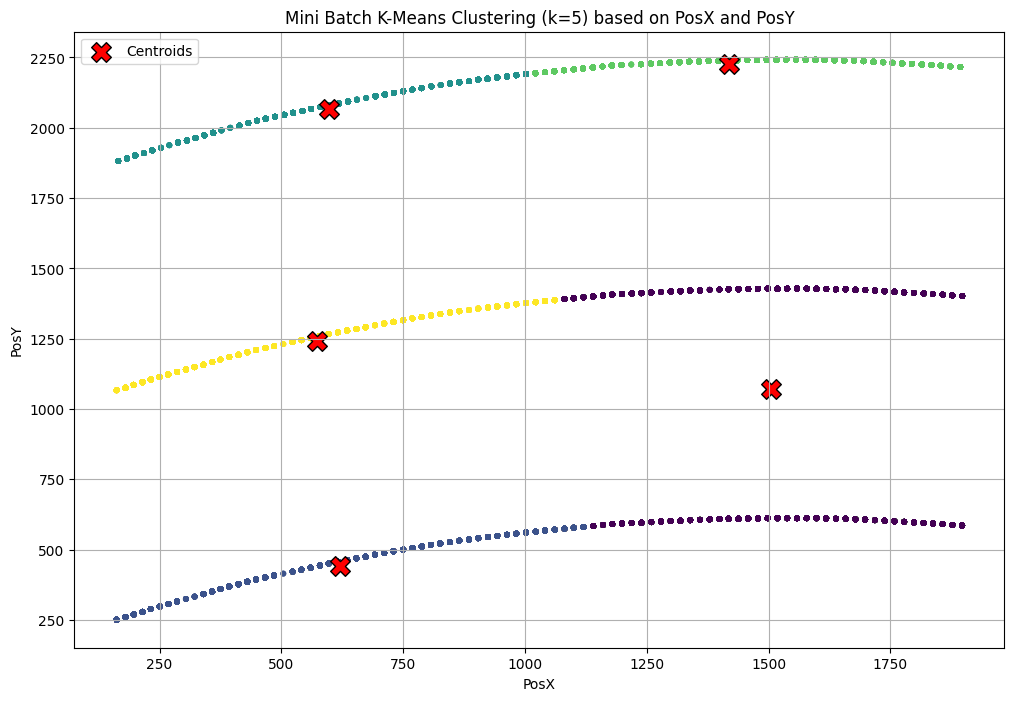

In [28]:
##### Visualizing the Clusters

## As we have clustered on PosX and PosY, we plot them and color them by their assigned cluster.
plt.figure(figsize=(12, 8))
plot_data = floor_plan_Kmeans.sample(n=min(50000, len(floor_plan_Kmeans)), random_state=42)

scatter = plt.scatter(plot_data['PosX'], plot_data['PosY'], c=plot_data['Cluster'], cmap='viridis', s=10, alpha=0.6)
## s=10      =====> size of the dots
## alpha=0.6 =====> the transparancy of the dots


## plotting the cluster-centers(Centroids)
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='red',
    marker='X', s=200,
    edgecolors='black',
    label='Centroids'
)



plt.title(f'Mini Batch K-Means Clustering (k={optimal_k}) based on PosX and PosY')
plt.xlabel('PosX')
plt.ylabel('PosY')
plt.grid(True)
plt.legend()
plt.show()


SSID     HV-COF  HV-GUEST  HV-HYBRID  HV-INTERNAL  eduroam
Cluster                                                   
0         26198     27801      28053        24575    22412
1         14486     14939      14649        13998    12596
2         15662     17178      15909        14155    13987
3         17163     18356      18888        15479    13974
4         18026     18919      19263        16988    14160


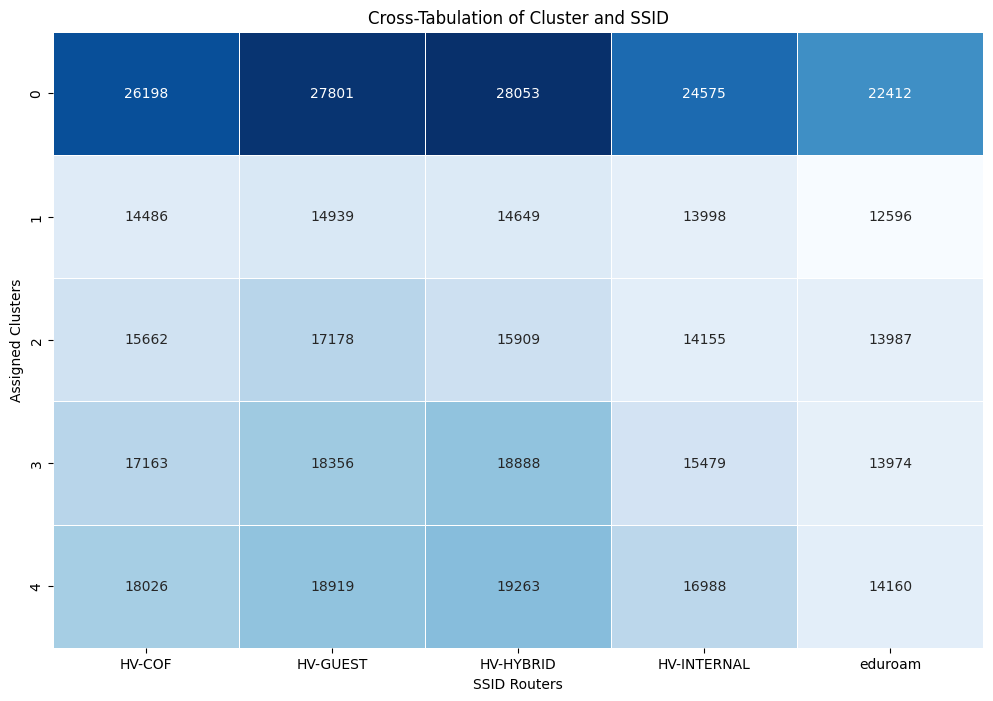

In [33]:
cross_tab = pd.crosstab(floor_plan_Kmeans['Cluster'], floor_plan_Kmeans['SSID'])
plt.figure(figsize=(12, 8))
sns.heatmap(cross_tab, annot=True, cmap='Blues', fmt='d', linewidths=0.5, cbar=False)
plt.title("Cross-Tabulation of Cluster and SSID")
plt.xlabel("SSID Routers")
plt.ylabel("Assigned Clusters")

print(cross_tab)

PosZ         2      3      4
Cluster                     
0            0  74411  54628
1            0      0  70668
2        76891      0      0
3        83860      0      0
4            0  87356      0


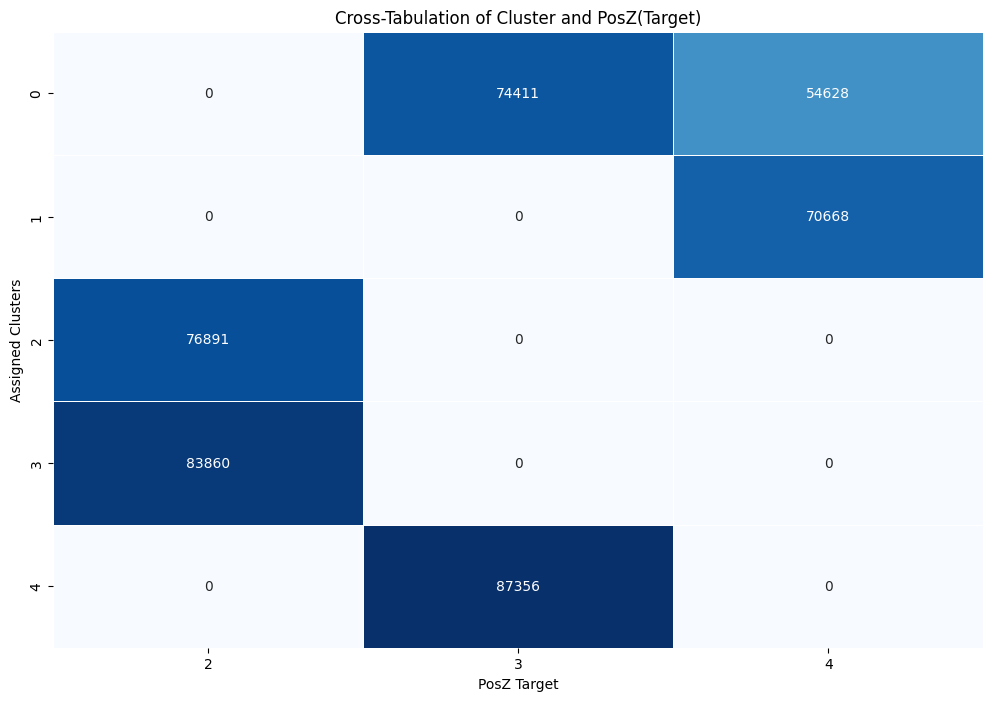

In [34]:
cross_tab = pd.crosstab(floor_plan_Kmeans['Cluster'], floor_plan_Kmeans['PosZ'])
plt.figure(figsize=(12, 8))
sns.heatmap(cross_tab, annot=True, cmap='Blues', fmt='d', linewidths=0.5, cbar=False)
plt.title("Cross-Tabulation of Cluster and PosZ(Target)")
plt.xlabel("PosZ Target")
plt.ylabel("Assigned Clusters")

print(cross_tab)